<a href="https://colab.research.google.com/github/sileysa/PCVK26_26_SILEYSA/blob/main/Week6_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Cell Identitas

In [6]:
# ============================================
# IDENTITAS
# ============================================

NAMA = 'Sileysa Faedatul Nuraini'
NIM = '244107020231'

print(NAMA, NIM)

Sileysa Faedatul Nuraini 244107020231


# 2a. Membuat Week6_26.ipynb

In [7]:
import numpy as np

def konvolusi(image, kernel):
    # Ukuran gambar
    tinggi, lebar = image.shape

    # Ukuran kernel
    k_tinggi, k_lebar = kernel.shape

    # Padding
    pad_tinggi = k_tinggi // 2
    pad_lebar = k_lebar // 2

    # Membuat gambar hasil
    hasil = np.zeros((tinggi, lebar), dtype=np.float32)

    # Padding gambar dengan nilai 0
    image_pad = np.pad(
        image,
        ((pad_tinggi, pad_tinggi),
         (pad_lebar, pad_lebar)),
        mode='constant',
        constant_values=0
    )

    # Proses konvolusi
    for i in range(tinggi):
        for j in range(lebar):

            # Mengambil area sesuai ukuran kernel
            area = image_pad[
                i:i + k_tinggi,
                j:j + k_lebar
            ]

            # Perkalian kernel dengan area gambar
            hasil[i, j] = np.sum(area * kernel)

    # Membatasi nilai pixel 0-255
    hasil = np.clip(hasil, 0, 255)

    return hasil.astype(np.uint8)

# 2b. Mount Google Drive

In [8]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2b. Import Library

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math

from google.colab.patches import cv2_imshow
from PIL import Image as im

# 2c. Fungsi convolution2d()

In [12]:
# ============================================
# KONVOLUSI TANPA LIBRARY
# ============================================

def convolution2d(image, kernel, stride, padding):
    # Mendapatkan ukuran gambar
    image_height, image_width = image.shape

    # Mendapatkan ukuran kernel
    kernel_height, kernel_width = kernel.shape

    # Menambahkan padding pada gambar
    padded_image = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode='constant',
        constant_values=0
    )

    # Ukuran hasil konvolusi
    output_height = (
        (image_height + 2 * padding - kernel_height)
        // stride
    ) + 1

    output_width = (
        (image_width + 2 * padding - kernel_width)
        // stride
    ) + 1

    # Membuat matriks hasil
    output = np.zeros(
        (output_height, output_width),
        dtype=np.float32
    )

    # Proses konvolusi
    for i in range(output_height):
        for j in range(output_width):

            # Posisi awal kernel
            row_start = i * stride
            col_start = j * stride

            # Mengambil area gambar sesuai ukuran kernel
            region = padded_image[
                row_start:row_start + kernel_height,
                col_start:col_start + kernel_width
            ]

            # Perkalian elemen kernel dengan piksel
            output[i, j] = np.sum(region * kernel)

    # Membatasi nilai piksel 0-255
    output = np.clip(output, 0, 255)

    return output.astype(np.uint8)

# 2d — Load Citra & Grayscale

In [15]:
# ============================================
# LOAD CITRA DAN UBAH KE GRAYSCALE
# ============================================

img = cv.imread(
    '/content/drive/MyDrive/PCVK/Images/mandrill.tiff'
)

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

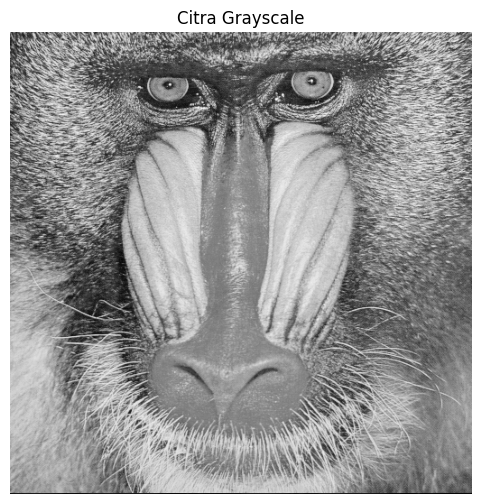

In [16]:
# Menampilkan citra grayscale

plt.figure(figsize=(8, 6))
plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.title('Citra Grayscale')
plt.show()

# 2e — Kernel Sharpening

In [17]:
# ============================================
# KERNEL SHARPENING
# ============================================

kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

print("Kernel Sharpening:")
print(kernel_sharpen)

Kernel Sharpening:
[[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]


# 2f  Konvolusi + tampilkan hasil

In [18]:
# ============================================
# KONVOLUSI SHARPENING
# ============================================

hasil_sharpen = convolution2d(
    img_gray,
    kernel_sharpen,
    1,
    2
)

print("Konvolusi sharpening berhasil!")

Konvolusi sharpening berhasil!


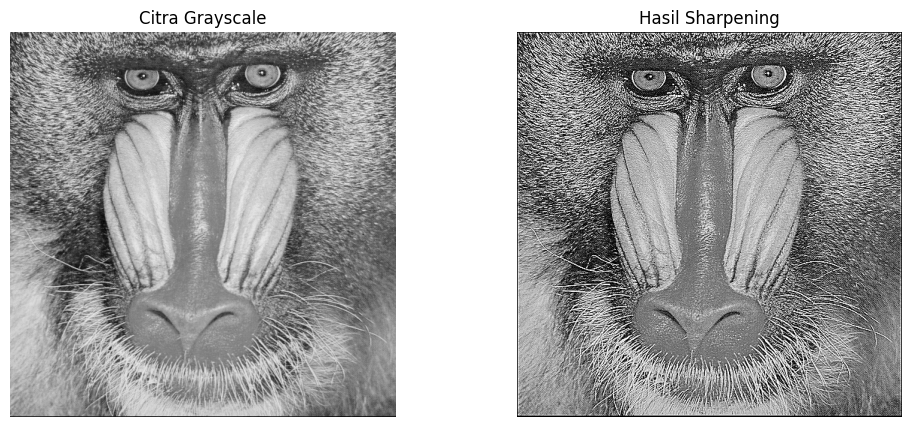

In [19]:
# ============================================
# MENAMPILKAN HASIL KONVOLUSI
# ============================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil_sharpen, cmap='gray')
plt.title('Hasil Sharpening')
plt.axis('off')

plt.show()

# Poin 3 — Filter Emboss

In [23]:
# ============================================
# POIN 3 - IMAGE FILTER
# ============================================

# --------------------------------------------
# 1. SHARPEN
# --------------------------------------------

kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

hasil_sharpen = convolution2d(
    img_gray,
    kernel_sharpen,
    1,
    2
)


# --------------------------------------------
# 2. EMBOSS
# --------------------------------------------

kernel_emboss = np.array([
    [-2, -1, 0],
    [-1,  1, 1],
    [ 0,  1, 2]
])

hasil_emboss = convolution2d(
    img_gray,
    kernel_emboss,
    1,
    2
)


# --------------------------------------------
# 3. LEFT SOBEL EDGE DETECTION
# --------------------------------------------

kernel_sobel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
])

hasil_sobel = convolution2d(
    img_gray,
    kernel_sobel,
    1,
    2
)


# --------------------------------------------
# 4. CANNY EDGE DETECTION
# --------------------------------------------

kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

hasil_canny = convolution2d(
    img_gray,
    kernel_canny,
    1,
    2
)


# --------------------------------------------
# 5. 21x21 GAUSSIAN BLUR
# --------------------------------------------

kernel_size = 21

sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(
    kernel_size,
    sigma
)

gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

hasil_gaussian = convolution2d(
    img_gray,
    gauss_kernel,
    1,
    10
)


print("Semua filter berhasil diproses!")

Semua filter berhasil diproses!


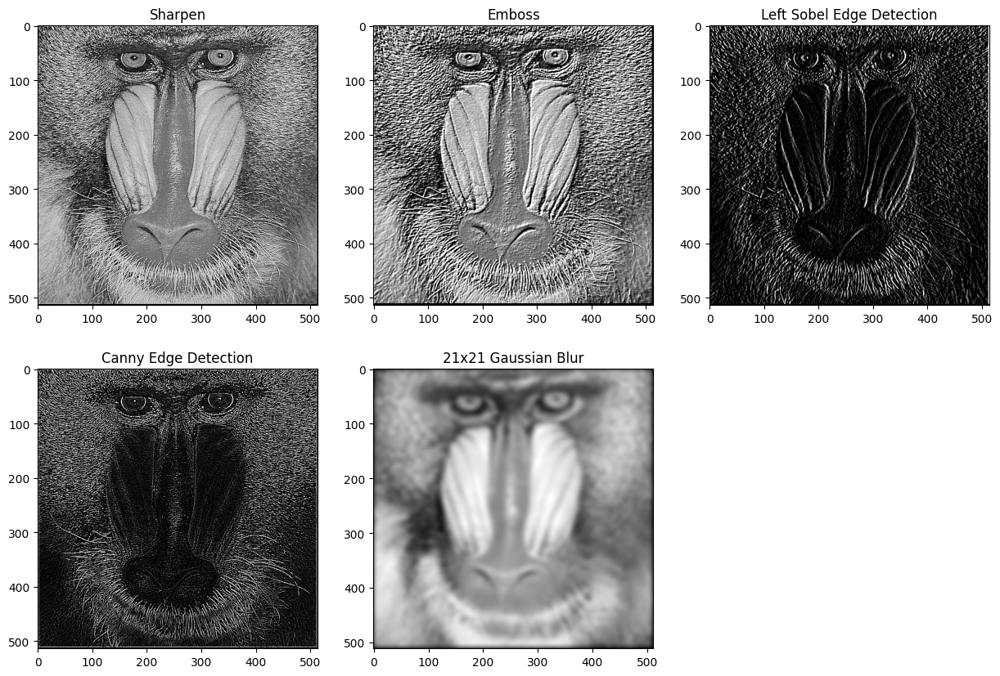

In [26]:
# ============================================
# MENAMPILKAN 5 HASIL FILTER
# ============================================

plt.figure(figsize=(15, 10))

# 1. Sharpen
plt.subplot(2, 3, 1)
plt.imshow(hasil_sharpen, cmap='gray')
plt.title('Sharpen')

# 2. Emboss
plt.subplot(2, 3, 2)
plt.imshow(hasil_emboss, cmap='gray')
plt.title('Emboss')

# 3. Left Sobel
plt.subplot(2, 3, 3)
plt.imshow(hasil_sobel, cmap='gray')
plt.title('Left Sobel Edge Detection')

# 4. Canny
plt.subplot(2, 3, 4)
plt.imshow(hasil_canny, cmap='gray')
plt.title('Canny Edge Detection')

# 5. Gaussian
plt.subplot(2, 3, 5)
plt.imshow(hasil_gaussian, cmap='gray')
plt.title('21x21 Gaussian Blur')

plt.show()

# E. FILTER LIBRARY DAN FILTER MODERN

## Buat fungsi show_side_by_side

In [27]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)

    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i + 1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

        plt.title(title)
        plt.axis("off")

    plt.show()

## Load gambar

In [28]:
# Load image
img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/lena.jpg"
)

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

## Gaussian Blur

In [29]:
blur = cv.GaussianBlur(img, (7, 7), 1)

## Canny Edge Detection

In [30]:
edges = cv.Canny(
    cv.cvtColor(img, cv.COLOR_BGR2GRAY),
    100,
    200
)

## Sharpen menggunakan cv.filter2D()

In [31]:
sharpen_kernel = np.array([[0,-1,0],
                           [-1,5,-1],
                           [0,-1,0]])

sharpened = cv.filter2D(img, -1, sharpen_kernel)

## Tampilkan gambar

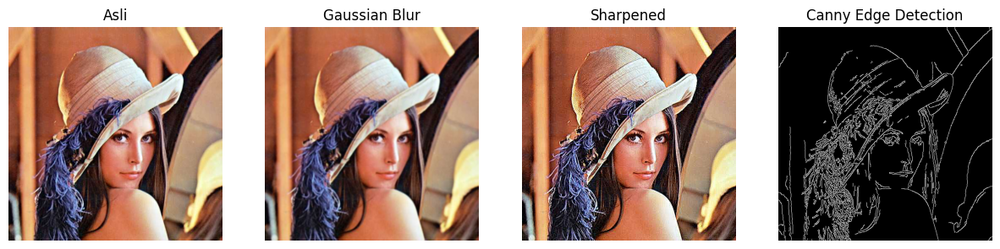

In [32]:
show_side_by_side(
    [img, blur, sharpened, edges],
    [
        "Asli",
        "Gaussian Blur",
        "Sharpened",
        "Canny Edge Detection"
    ]
)

# Percobaan 2 — Filter Modern

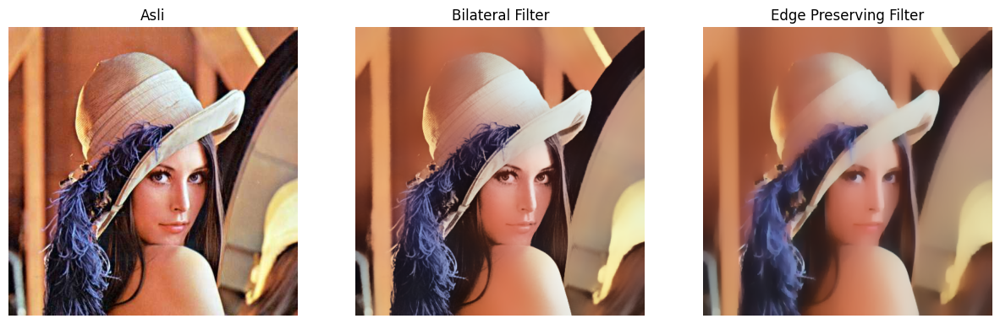

In [33]:
# ============================================
# E. PERCOBAAN 2 - FILTER MODERN DARI OPENCV
# ============================================

# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter
edge_preserve = cv.edgePreservingFilter(
    img,
    flags=1,
    sigma_s=100,
    sigma_r=0.9
)

# Menampilkan hasil berdampingan
show_side_by_side(
    [img, bilateral, edge_preserve],
    [
        "Asli",
        "Bilateral Filter",
        "Edge Preserving Filter"
    ]
)

# Percobaan 3 — Feature Map pada CNN

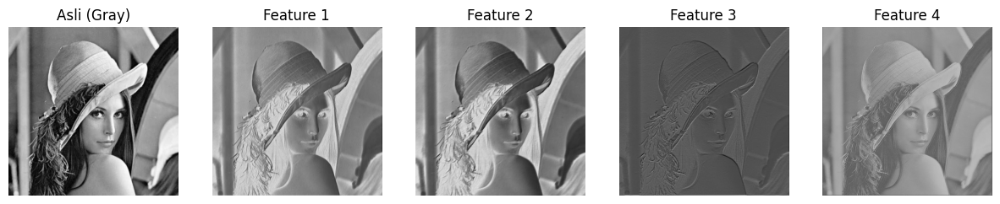

In [34]:
# ============================================
# E. PERCOBAAN 3 - FEATURE MAP PADA CNN
# ============================================

import torch
import torch.nn as nn


# Membuat model CNN sederhana
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            1,
            4,
            kernel_size=3,
            stride=1,
            padding=1
        )

    def forward(self, x):
        return self.conv1(x)


# Membuat model
model = SimpleCNN()


# Mengubah gambar grayscale menjadi tensor
img_tensor = (
    torch.tensor(
        img_gray,
        dtype=torch.float32
    )
    .unsqueeze(0)
    .unsqueeze(0)
    / 255.0
)


# Menghasilkan Feature Map
with torch.no_grad():
    features = model(img_tensor)


# Mengubah Feature Map menjadi gambar
feature_maps = [
    features[0, i].numpy()
    for i in range(features.shape[1])
]


# Menampilkan gambar asli dan Feature Map
show_side_by_side(
    [img_gray] + feature_maps,
    ["Asli (Gray)"] +
    [f"Feature {i+1}" for i in range(len(feature_maps))]
)

Berdasarkan hasil percobaan, proses convolution pada CNN menghasilkan beberapa Feature Map dari satu citra masukan. Pada percobaan ini digunakan 4 filter sehingga dihasilkan 4 Feature Map. Setiap Feature Map dapat menampilkan pola atau karakteristik citra yang berbeda. Ketika kode dijalankan beberapa kali, hasil Feature Map dapat berubah karena bobot filter pada model CNN diinisialisasi secara acak. Hal ini menunjukkan bahwa convolution pada CNN digunakan untuk mengekstraksi fitur dari citra melalui filter yang berbeda.

# Percobaan 4 — Beauty Filter dan Old/Vintage Filter

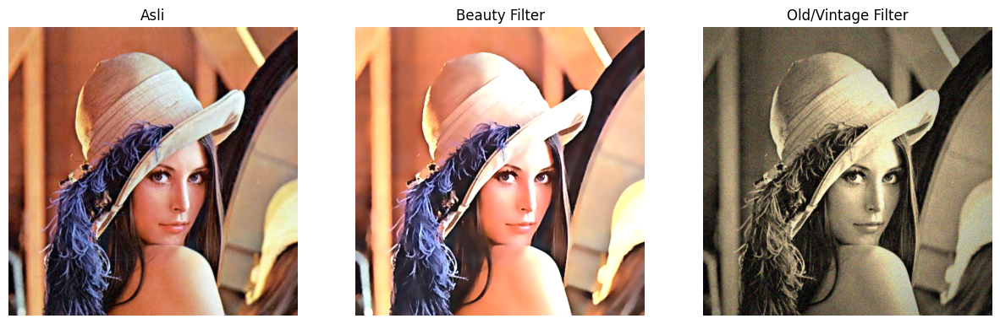

In [35]:
# ============================================
# E. PERCOBAAN 4
# BEAUTY FILTER & OLD/VINTAGE FILTER
# ============================================

# ============================================
# 1. BEAUTY FILTER
# ============================================

# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(
    img,
    d=15,
    sigmaColor=75,
    sigmaSpace=75
)

# Step 2: Sharpen ringan
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)

sharpened = cv.addWeighted(
    smooth,
    1.5,
    gaussian,
    -0.5,
    0
)

# Step 3: Brightness & Contrast
alpha = 1.2
beta = 15

beauty = cv.convertScaleAbs(
    sharpened,
    alpha=alpha,
    beta=beta
)


# ============================================
# 2. OLD / VINTAGE FILTER
# ============================================

# Step 1: Sepia tone
sepia_kernel = np.array([
    [0.272, 0.534, 0.131],
    [0.349, 0.686, 0.168],
    [0.393, 0.769, 0.189]
])

sepia = cv.transform(img, sepia_kernel)

sepia = np.clip(
    sepia,
    0,
    255
).astype(np.uint8)


# Step 2: Vignette
rows, cols = img.shape[:2]

kernel_x = cv.getGaussianKernel(
    cols,
    cols * 0.6
)

kernel_y = cv.getGaussianKernel(
    rows,
    rows * 0.6
)

kernel = kernel_y * kernel_x.T

mask = kernel / kernel.max()

vignette = sepia.copy()

for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask


# Step 3: Noise / Grain
noise = np.random.normal(
    0,
    15,
    vignette.shape
).astype(np.int16)

old_img = np.clip(
    vignette.astype(np.int16) + noise,
    0,
    255
).astype(np.uint8)


# ============================================
# MENAMPILKAN HASIL
# ============================================

show_side_by_side(
    [img, beauty, old_img],
    [
        "Asli",
        "Beauty Filter",
        "Old/Vintage Filter"
    ]
)

# Percobaan 5 — Filter Anime / Cartoon

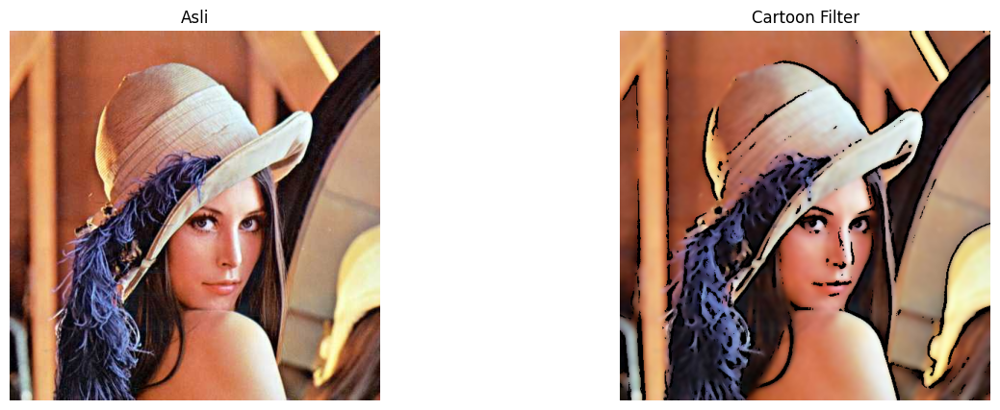

In [36]:
# ============================================
# E. PERCOBAAN 5 - FILTER ANIME / CARTOON
# ============================================

# Step 1: Edge Detection
# Pakai median blur terlebih dahulu agar gambar lebih halus
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

gray_blur = cv.medianBlur(gray, 7)

edges = cv.adaptiveThreshold(
    gray_blur,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    9,
    9
)


# Step 2: Bilateral Filter untuk smoothing warna
color = cv.bilateralFilter(
    img,
    d=9,
    sigmaColor=200,
    sigmaSpace=200
)


# Step 3: Gabungkan warna dan edge
cartoon = cv.bitwise_and(
    color,
    color,
    mask=edges
)


# Tampilkan hasil
show_side_by_side(
    [img, cartoon],
    [
        "Asli",
        "Cartoon Filter"
    ]
)

# Percobaan 6 — Night Filter

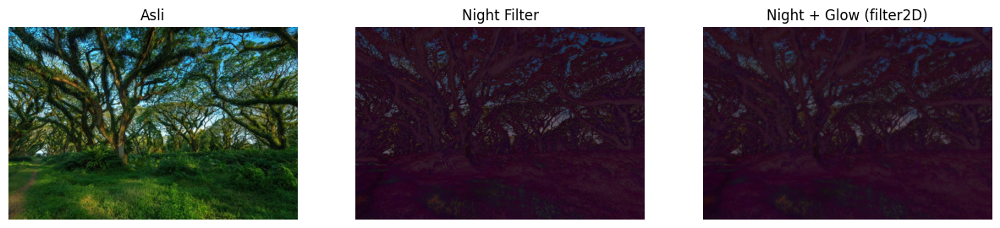

In [38]:
# ============================================
# E. PERCOBAAN 6 - NIGHT FILTER
# ============================================

# Load gambar
img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/djawatan.jpg"
)

img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


# Step 1: Gelapkan gambar
# Contrast turun dan brightness dikurangi
night = cv.convertScaleAbs(
    img,
    alpha=0.6,
    beta=-40
)


# Step 2: Tambahkan bias biru
blue_tint = np.full_like(
    night,
    (50, 0, 100)
)

night = cv.addWeighted(
    night,
    0.8,
    blue_tint,
    0.2,
    0
)


# Step 3: Efek glow di area terang dengan filter2D
kernel = np.ones(
    (15, 15),
    np.float32
) / 225

glow = cv.filter2D(
    night,
    -1,
    kernel
)


# Kombinasikan night + glow
night_glow = cv.addWeighted(
    night,
    0.7,
    glow,
    0.3,
    0
)


# Tampilkan hasil
show_side_by_side(
    [img, night, night_glow],
    [
        "Asli",
        "Night Filter",
        "Night + Glow (filter2D)"
    ]
)

# Percobaan 6 — Morning Filter + Efek Kabut

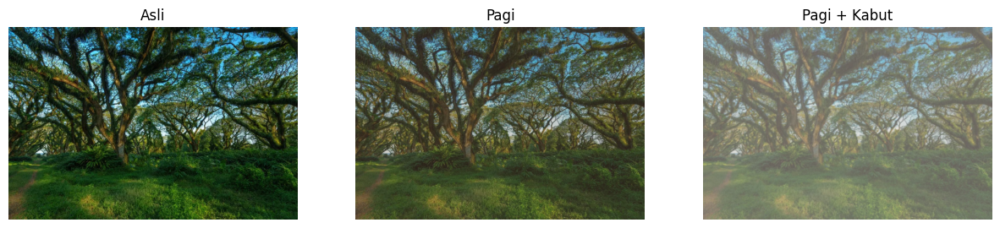

In [39]:
# Filter Suasana pagi dan Kabut
# ==========================
# Step 1: Kurangi kontras & cerahkan
# ==========================
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# ==========================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# ==========================
warm_tint = np.full_like(
    soft,
    (40, 70, 120)
)   # BGR

pagi = cv.addWeighted(
    soft,
    0.8,
    warm_tint,
    0.2,
    0
)

# ========================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# ========================
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(
    kabut,
    0.7,
    white_layer,
    0.3,
    0
)

# Tampilkan hasil
show_side_by_side(
    [img, pagi, kabut],
    [
        "Asli",
        "Pagi",
        "Pagi + Kabut"
    ]
)

# 1(a). Tambahkan Noise Salt and Pepper

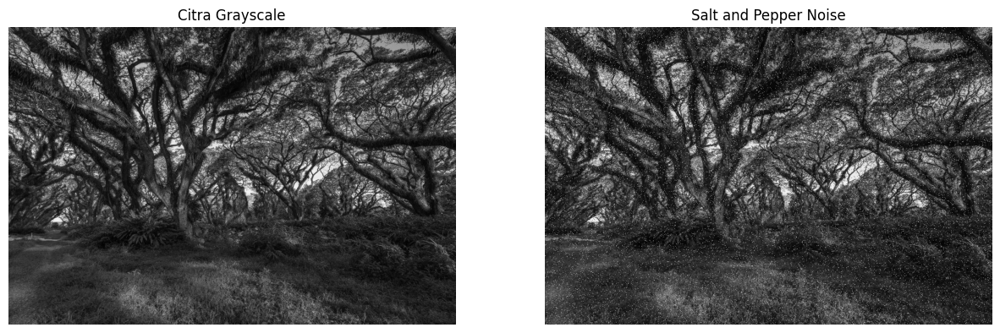

In [40]:
# ============================================
# TUGAS ANALISIS 1
# Mean Filter vs Median Filter
# ============================================

# Citra grayscale
gray = img_gray.copy()

# Fungsi untuk menambahkan Salt and Pepper Noise
def add_salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    # Jumlah piksel yang diberi noise
    total_pixels = image.size
    num_noise = int(amount * total_pixels)

    # Salt noise (putih)
    salt_coords = (
        np.random.randint(0, image.shape[0], num_noise // 2),
        np.random.randint(0, image.shape[1], num_noise // 2)
    )

    noisy[salt_coords] = 255

    # Pepper noise (hitam)
    pepper_coords = (
        np.random.randint(0, image.shape[0], num_noise // 2),
        np.random.randint(0, image.shape[1], num_noise // 2)
    )

    noisy[pepper_coords] = 0

    return noisy


# Tambahkan Salt and Pepper Noise
noisy = add_salt_pepper_noise(gray, amount=0.05)


# Tampilkan citra asli dan citra yang sudah diberi noise
show_side_by_side(
    [gray, noisy],
    [
        "Citra Grayscale",
        "Salt and Pepper Noise"
    ]
)

# 1(b). Mean Filter dan Median Filter

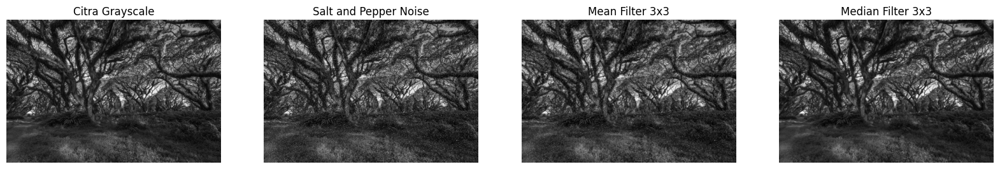

In [41]:
# ============================================
# 1(b) MEAN FILTER DAN MEDIAN FILTER
# ============================================

# Mean Filter 3x3
mean_filter = cv.blur(
    noisy,
    (3, 3)
)

# Median Filter 3x3
median_filter = cv.medianBlur(
    noisy,
    3
)


# Tampilkan semua hasil
show_side_by_side(
    [
        gray,
        noisy,
        mean_filter,
        median_filter
    ],
    [
        "Citra Grayscale",
        "Salt and Pepper Noise",
        "Mean Filter 3x3",
        "Median Filter 3x3"
    ],
    figsize=(20, 5)
)

# 1(c). Analisis mengapa Median Filter jauh lebih bersih dalam menghapus noise tersebut dibanding Mean Filter.

Mean Filter menghitung nilai rata-rata dari piksel pada area 3×3 sehingga piksel noise yang memiliki nilai ekstrem, yaitu 0 atau 255, ikut memengaruhi nilai hasil filter. Akibatnya, noise dapat menyebar ke piksel di sekitarnya dan citra menjadi lebih blur. Sedangkan Median Filter mengurutkan nilai piksel pada area 3×3 kemudian mengambil nilai tengahnya. Piksel Salt and Pepper yang memiliki nilai ekstrem tidak terlalu memengaruhi nilai median. Oleh karena itu, Median Filter lebih efektif dalam menghilangkan noise Salt and Pepper sekaligus mempertahankan tepi dan detail objek pada citra. Dari hasil pengamatan visual, Median Filter menghasilkan citra yang lebih bersih dan lebih mempertahankan detail dibandingkan Mean Filter.

# 2(a). Membuat Kernel Sharpening 3×3 dan 5×5

In [42]:
# ============================================
# TUGAS EVALUASI 2
# PEMILIHAN UKURAN KERNEL SHARPENING
# ============================================

# Kernel Sharpening 3x3
kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)


# Kernel Sharpening 5x5
kernel_sharpen_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1],
    [-1, -1, 25, -1, -1],
    [-1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32)

# 2(b). Terapkan ke citra yang sedikit buram

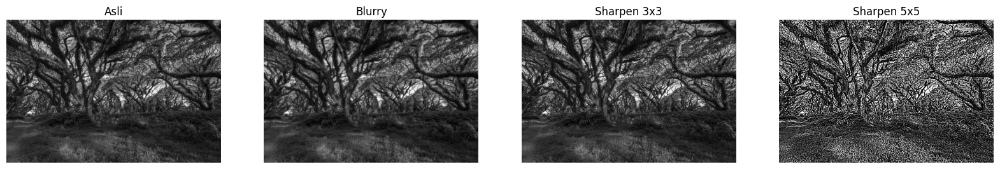

In [43]:
# ============================================
# 2(b) MEMBUAT CITRA BLURRY
# ============================================

# Membuat citra sedikit buram
blurry = cv.GaussianBlur(
    img_gray,
    (5, 5),
    1
)


# Terapkan sharpening 3x3
sharp_3x3 = cv.filter2D(
    blurry,
    -1,
    kernel_sharpen_3x3
)


# Terapkan sharpening 5x5
sharp_5x5 = cv.filter2D(
    blurry,
    -1,
    kernel_sharpen_5x5
)


# Tampilkan hasil
show_side_by_side(
    [
        img_gray,
        blurry,
        sharp_3x3,
        sharp_5x5
    ],
    [
        "Asli",
        "Blurry",
        "Sharpen 3x3",
        "Sharpen 5x5"
    ],
    figsize=(20, 5)
)

# Tentukan kernel mana yang paling optimal untuk digunakan sehari-hari

Berdasarkan hasil pengujian, kernel Sharpen 3×3 lebih optimal dibandingkan Sharpen 5×5. Sharpen 3×3 mampu meningkatkan kejelasan tepi gambar tanpa menghasilkan noise yang berlebihan. Sementara itu, Sharpen 5×5 menghasilkan tepi yang lebih tajam, tetapi juga memperkuat noise sehingga gambar terlihat kasar dan kurang natural. Oleh karena itu, kernel 3×3 dipilih sebagai kernel yang paling optimal untuk penggunaan sehari-hari karena memberikan keseimbangan antara ketajaman dan kualitas gambar.

# 3(a). Buat fungsi kartun(image)

In [44]:
# ============================================
# 3. TUGAS KREASI - FILTER KARTUN
# ============================================

def kartun(image):
    # 1. Penghalusan warna menggunakan Bilateral Filter
    smooth = cv.bilateralFilter(
        image,
        d=9,
        sigmaColor=200,
        sigmaSpace=200
    )

    # 2. Ubah gambar menjadi grayscale
    gray = cv.cvtColor(
        image,
        cv.COLOR_BGR2GRAY
    )

    # 3. Kurangi noise sebelum deteksi tepi
    gray_blur = cv.medianBlur(
        gray,
        7
    )

    # 4. Deteksi garis tepi menggunakan Adaptive Thresholding
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # 5. Gabungkan warna halus dengan garis tepi
    cartoon_image = cv.bitwise_and(
        smooth,
        smooth,
        mask=edges
    )

    return cartoon_image

# 3(b). Tampilkan hasil

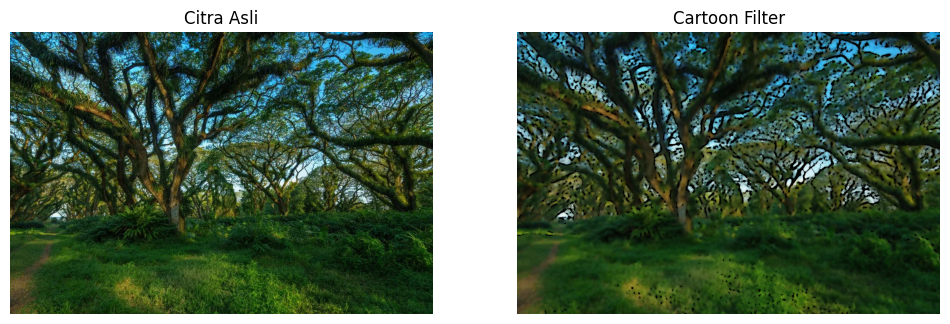

In [45]:
# ============================================
# MENAMPILKAN HASIL FILTER KARTUN
# ============================================

hasil_kartun = kartun(img)

show_side_by_side(
    [
        img,
        hasil_kartun
    ],
    [
        "Citra Asli",
        "Cartoon Filter"
    ],
    figsize=(12, 5)
)